In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [27]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

n = 30
baseline = rng.normal(60, 8, n)

df = pd.DataFrame({
    "student": range(1, n + 1),
    "Test1": np.round(baseline + rng.normal(0, 3, n), 1),
    "Test2": np.round(baseline + 4 + rng.normal(0, 3, n), 1),
    "Test3": np.round(baseline + 8 + rng.normal(0, 3, n), 1)
})

df

,student,Test1,Test2,Test3
0,1,68.9,61.4,72.4
1,2,50.5,54.7,59.4
2,3,64.5,70.5,72.7
3,4,65.1,73.3,75.3
4,5,46.2,50.5,47.3
5,6,53.0,56.0,53.2
6,7,60.7,64.0,65.1
7,8,54.9,60.1,62.5
8,9,57.4,66.4,69.1
9,10,55.1,56.6,58.5


In [29]:
df[["Test1", "Test2", "Test3"]].mean()

Test1    60.483333
Test2    63.836667
Test3    67.320000
dtype: float64

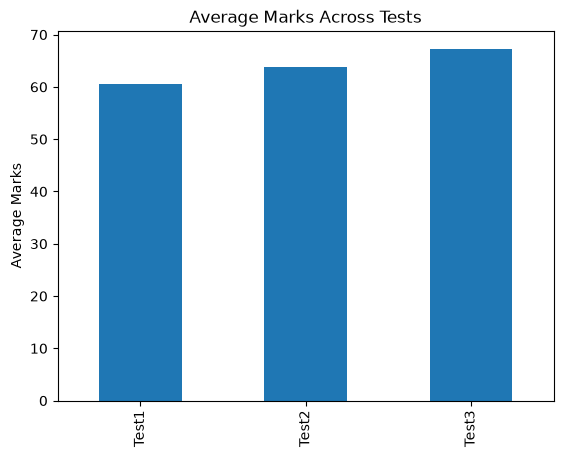

In [30]:
df[["Test1", "Test2", "Test3"]].mean().plot(kind="bar")

plt.ylabel("Average Marks")
plt.title("Average Marks Across Tests")
plt.show()

In [31]:
long_df = df.melt(
    id_vars="student",
    var_name="test",
    value_name="marks"
)

long_df.head(9)

,student,test,marks
0,1,Test1,68.9
1,2,Test1,50.5
2,3,Test1,64.5
3,4,Test1,65.1
4,5,Test1,46.2
5,6,Test1,53.0
6,7,Test1,60.7
7,8,Test1,54.9
8,9,Test1,57.4


In [32]:
from scipy.stats import shapiro

for a, b in [("Test1", "Test2"),
             ("Test1", "Test3"),
             ("Test2", "Test3")]:

    diff = df[a] - df[b]
    stat, p = shapiro(diff)

    print(f"{a} vs {b}: p-value = {p:.4f}")

Test1 vs Test2: p-value = 0.0636
Test1 vs Test3: p-value = 0.6008
Test2 vs Test3: p-value = 0.3678


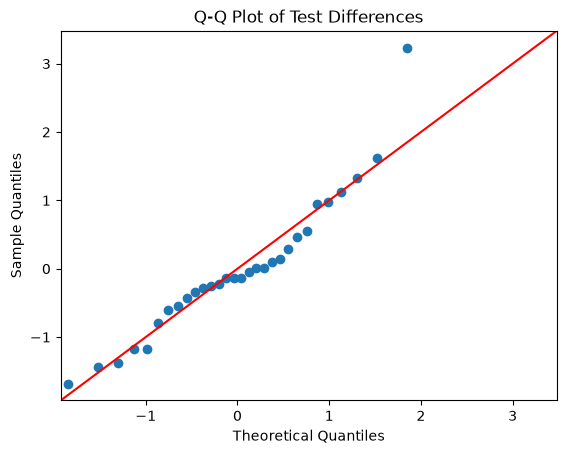

In [34]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

diff = df["Test1"] - df["Test2"]

sm.qqplot(diff, line="45", fit=True)
plt.title("Q-Q Plot of Test Differences")
plt.show()

In [35]:
!pip install pingouin

  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.3 MB 1.7 MB/s eta 0:00:05
   ----- ---------------------------------- 1.0/8.3 MB 1.8 MB/s eta 0:00:05
   ------ --------------------------------- 1.3/8.3 MB 1.7 MB/s eta 0:00:05
   ------ --------------------------------- 1.3/8.3 MB 1.7 MB/s eta 0:00:05
   ------- -------------------------------- 1.6/8.3 MB 1.4 MB/s eta 0:00:05
   -------- ------------------------------- 1.8/8.3 MB 1.2 MB/s eta 0:00:06
   -------- ------------------------------- 1.8/8.3 MB 1.2 MB/s eta 0:00:06
   ---------- ----------------------------- 2.1/8.3 MB 1.1 MB/s eta 0:00:06
   ---------- ----------------------------- 2.1/8.3 MB

In [36]:
import pingouin as pg

pg.sphericity(
    data=long_df,
    dv="marks",
    within="test",
    subject="student"
)

SpherResults(spher=True, W=np.float64(0.9991488481026711), chi2=np.float64(0.023842401317786255), dof=2, pval=np.float64(0.9881495753295857))

In [37]:
from statsmodels.stats.anova import AnovaRM

model = AnovaRM(
    data=long_df,
    depvar="marks",
    subject="student",
    within=["test"]
)

result = model.fit()

print(result)

              Anova
     F Value Num DF  Den DF Pr > F
----------------------------------
test 59.9229 2.0000 58.0000 0.0000



In [38]:
anova_table = result.anova_table

F = anova_table.loc["test", "F Value"]
df_effect = anova_table.loc["test", "Num DF"]
df_error = anova_table.loc["test", "Den DF"]

partial_eta_sq = (F * df_effect) / (
    F * df_effect + df_error
)

print("Partial eta-squared:", partial_eta_sq)

Partial eta-squared: 0.673874768546697


In [ ]:


pairwise = pg.pairwise_tests(
    data=long_df,
    dv="marks",
    within="test",
    subject="student",
    padjust="bonf"
)

pairwise[['A', 'B', 'T', 'p_corr']]

,A,B,T,p_corr
0,Test1,Test2,-5.379990,2.647594e-05
1,Test1,Test3,-10.801812,3.345113e-11
2,Test2,Test3,-5.642853,1.278144e-05


In [44]:
pairwise.columns

Index(['Contrast', 'A', 'B', 'Paired', 'Parametric', 'T', 'dof', 'alternative',
       'p_unc', 'p_corr', 'p_adjust', 'BF10', 'hedges'],
      dtype='str')

In [46]:
df[["Test1", "Test2", "Test3"]].mean()

Test1    60.483333
Test2    63.836667
Test3    67.320000
dtype: float64